# BEED Dataset - EEG Epileptic Seizure Detection

This dataset contains EEG (Electroencephalogram) recordings for epileptic seizure detection. It consists of 16 EEG channels recorded from different brain regions using the international 10-20 electrode placement system.

**About the Dataset:**
- **Subjects:** 80 individuals (20 per category)
- **Instances:** 8,000 samples (2,000 per class)
- **Features:** 16 EEG channels (X1-X16) representing electrical activity in microvolts (μV)
- **Sampling Rate:** 256 Hz over 20-second intervals
- **Classes:** 4 categories for seizure classification

**Target Variable (y):**
- `0` - Healthy subjects (control group)
- `1` - Generalized seizures
- `2` - Focal seizures
- `3` - Seizure events (including eye blinking, constant staring)

**Use Cases:**
- Multi-class seizure type classification
- Signal processing and pattern recognition
- Medical AI diagnostics and monitoring systems

## Import Required Libraries

In [129]:
# Install required packages (uncomment to run)
# !pip install torch

In [130]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

# Configure display settings
warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

## Load the Dataset

Loading the BEED EEG dataset for epileptic seizure detection.

In [131]:
# Load the BEED dataset
df = pd.read_csv("./data/raw/5_beed_bangalore_eeg_epilepsy_dataset.csv")

print(f"Dataset Shape: {df.shape}")
df.head(10)


Dataset Shape: (8000, 17)


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,y
0,4,7,18,25,28,27,20,10,-10,-18,-20,-16,13,32,12,10,0
1,87,114,120,106,76,54,28,5,-19,-49,-85,-102,-100,-89,-61,-21,0
2,-131,-133,-140,-131,-123,-108,-58,-51,-70,-77,-76,-76,-73,-57,-40,-14,0
3,68,104,73,34,-12,-26,-38,-36,-67,-88,-25,31,18,-4,6,-29,0
4,-67,-90,-97,-94,-86,-71,-43,-11,23,46,58,50,39,19,-9,-41,0
5,-47,-52,-45,-41,-29,-24,-21,-19,-13,-3,-2,4,11,14,11,14,0
6,-67,-30,7,33,51,79,105,122,132,115,83,42,10,-22,-47,-57,0
7,72,60,67,69,55,46,30,23,31,40,51,54,65,69,60,50,0
8,56,14,-12,-38,-73,-115,-137,-130,-78,-18,33,85,132,196,244,258,0
9,-17,-16,-12,13,53,84,77,57,24,-20,-39,-45,-40,-35,-19,-4,0


## Data Exploration

Understanding the structure, data types, and basic statistics of the EEG dataset.

In [132]:
# Dataset info
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 17 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   X1      8000 non-null   int64
 1   X2      8000 non-null   int64
 2   X3      8000 non-null   int64
 3   X4      8000 non-null   int64
 4   X5      8000 non-null   int64
 5   X6      8000 non-null   int64
 6   X7      8000 non-null   int64
 7   X8      8000 non-null   int64
 8   X9      8000 non-null   int64
 9   X10     8000 non-null   int64
 10  X11     8000 non-null   int64
 11  X12     8000 non-null   int64
 12  X13     8000 non-null   int64
 13  X14     8000 non-null   int64
 14  X15     8000 non-null   int64
 15  X16     8000 non-null   int64
 16  y       8000 non-null   int64
dtypes: int64(17)
memory usage: 1.0 MB


In [133]:
# Statistical summary
df.describe().T


,count,mean,std,min,25%,50%,75%,max
X1,8000.0,-1.490375,36.824213,-281.0,-7.00,0.0,8.00,252.0
X2,8000.0,-2.189375,36.108088,-255.0,-7.00,0.0,8.00,261.0
X3,8000.0,-3.237500,35.802490,-255.0,-7.00,-1.0,5.00,238.0
X4,8000.0,-4.119375,36.285268,-257.0,-10.00,-1.0,7.00,246.0
X5,8000.0,-1.821625,37.621284,-264.0,-10.00,0.0,10.00,249.0
X6,8000.0,-2.311750,36.306006,-277.0,-8.00,0.0,8.00,245.0
X7,8000.0,-3.398125,36.358395,-277.0,-8.00,-1.0,6.00,220.0
X8,8000.0,-3.448625,36.522214,-260.0,-7.00,-1.0,5.00,271.0
X9,8000.0,-1.647875,38.107721,-290.0,-7.00,0.0,8.00,280.0
X10,8000.0,-2.561250,37.540680,-302.0,-8.00,0.0,8.00,251.0


### Check for Missing Values

Verifying data quality by checking for null values in the dataset.

In [134]:
# Check for missing values
missing_values = df.isnull().sum()
print(f"Total missing values: {missing_values.sum()}")


Total missing values: 0


### Check for Duplicate Rows

Identifying duplicate entries to ensure data integrity.

In [135]:
# Check for duplicates
duplicated_rows = df[df.duplicated()]
print(f"Duplicated rows: {duplicated_rows.shape[0]} ({(duplicated_rows.shape[0]/len(df))*100:.2f}%)")


Duplicated rows: 0 (0.00%)


In [136]:
# Remove duplicates if any
if duplicated_rows.shape[0] > 0:
    df.drop_duplicates(inplace=True)
    print(f"Shape after removing duplicates: {df.shape}")
else:
    print("No duplicates found.")


No duplicates found.


In [137]:
# Unique value counts
unique_counts = {col: df[col].nunique() for col in df.columns}
pd.DataFrame(unique_counts, index=['Num_Unique']).T


,Num_Unique
X1,333
X2,348
X3,339
X4,345
X5,340
X6,340
X7,350
X8,350
X9,352
X10,351


## Exploratory Data Analysis (EDA)

Visualizing and analyzing the EEG data to understand patterns and class distributions.

### Target Variable Distribution

Analyzing the distribution of seizure classes to understand the class balance.

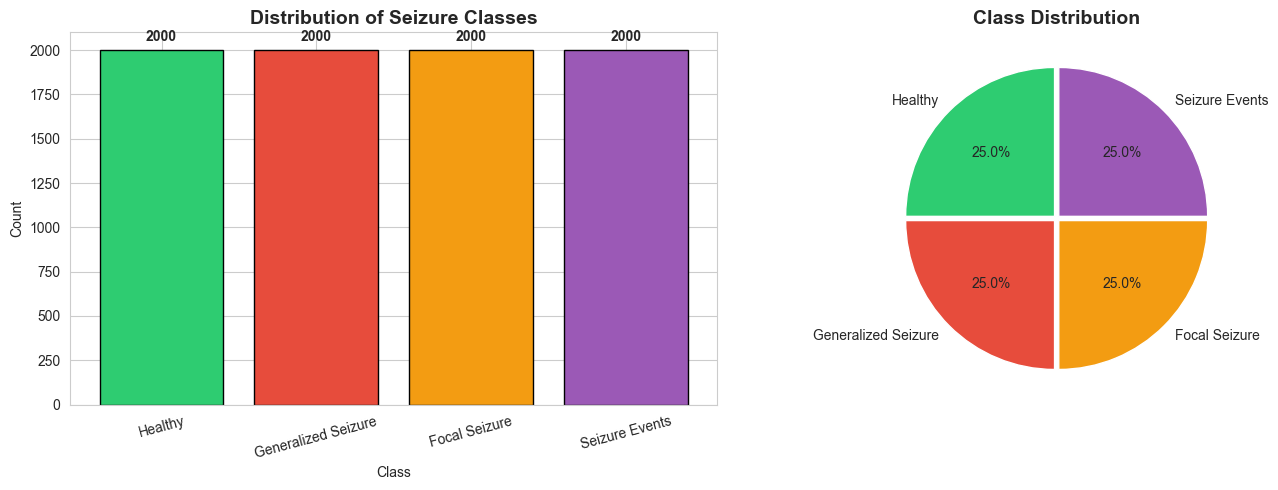

In [138]:
# Target variable distribution
class_labels = {
    0: 'Healthy',
    1: 'Generalized Seizure',
    2: 'Focal Seizure', 
    3: 'Seizure Events'
}

plt.figure(figsize=(14, 5))

# Bar plot
plt.subplot(1, 2, 1)
class_counts = df['y'].value_counts().sort_index()
colors = ['#2ecc71', '#e74c3c', '#f39c12', '#9b59b6']
bars = plt.bar(class_counts.index, class_counts.values, color=colors, edgecolor='black')
plt.title('Distribution of Seizure Classes', fontsize=14, fontweight='bold')
plt.xlabel('Class')
plt.ylabel('Count')
plt.xticks(class_counts.index, [class_labels[i] for i in class_counts.index], rotation=15)

# Add count labels
for bar, count in zip(bars, class_counts.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
             str(count), ha='center', fontsize=10, fontweight='bold')

# Pie chart
plt.subplot(1, 2, 2)
plt.pie(class_counts, labels=[class_labels[i] for i in class_counts.index], 
        autopct='%1.1f%%', colors=colors, startangle=90, explode=[0.02]*4)
plt.title('Class Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()


### EEG Channel Distributions

Visualizing the distribution of each EEG channel to understand signal characteristics.

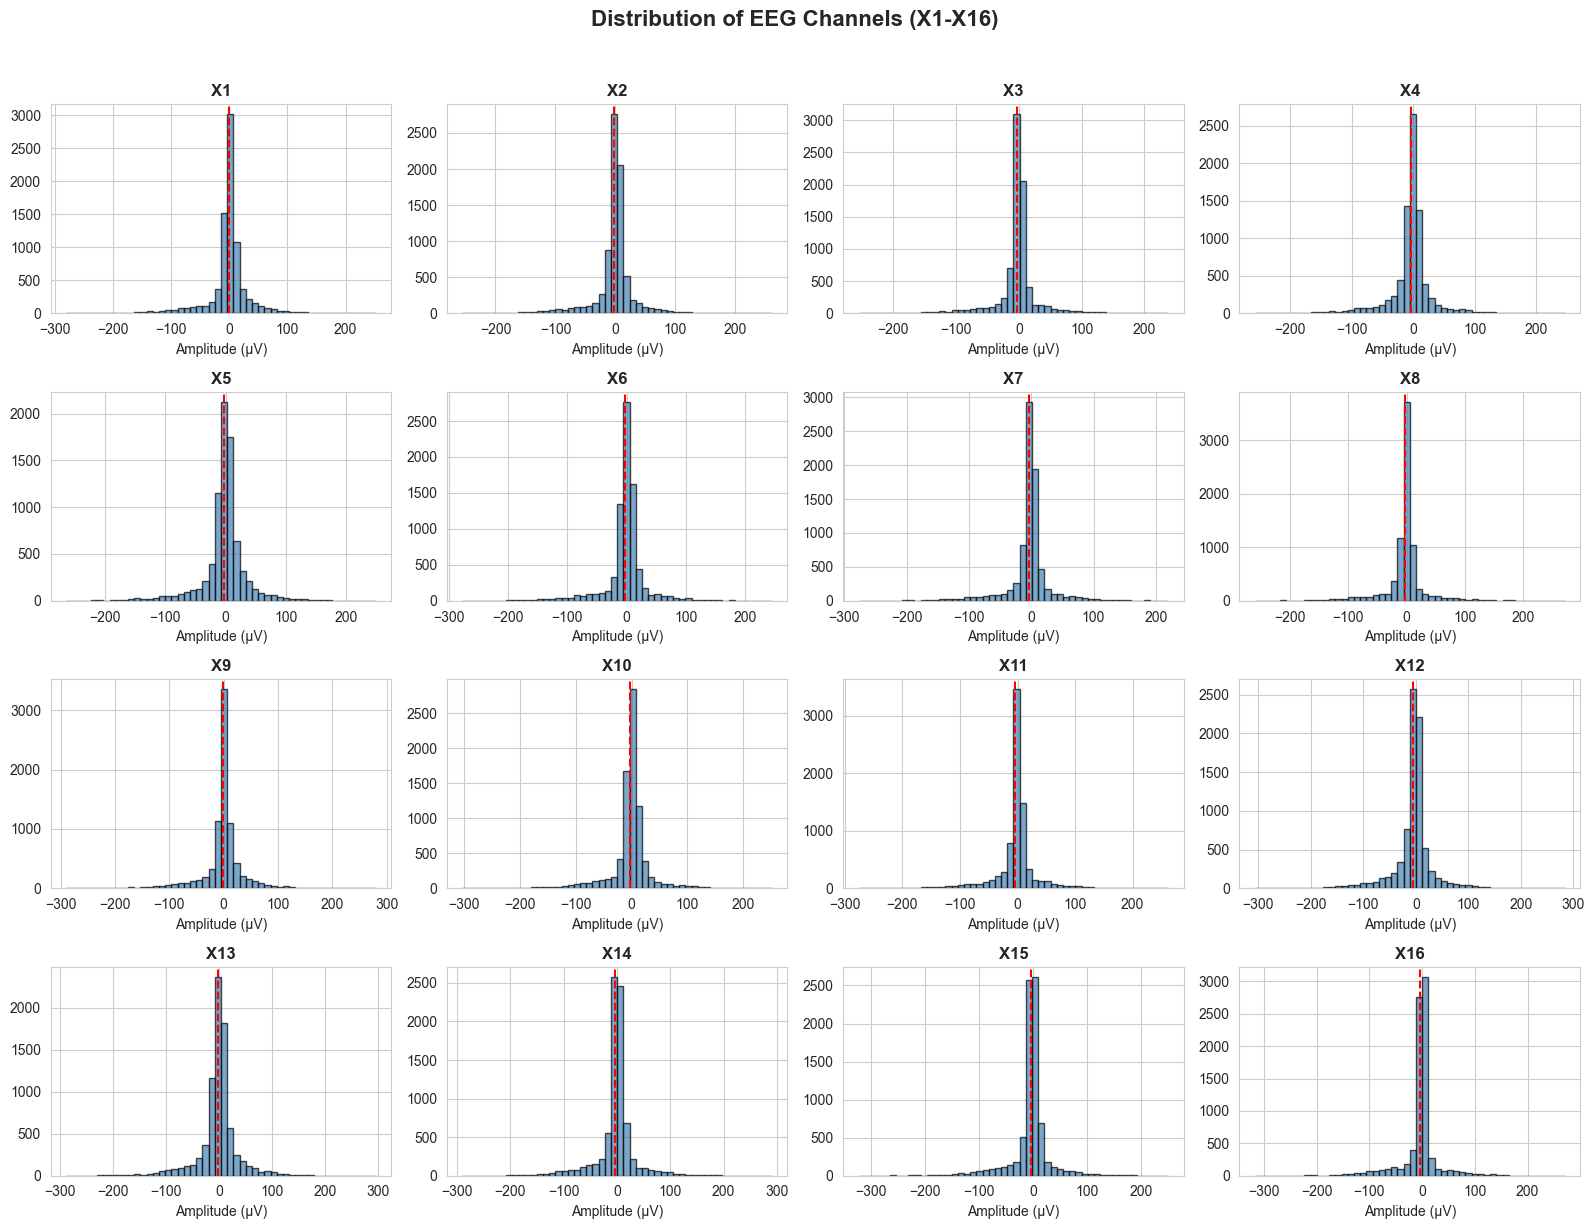

In [139]:
# Distribution of all EEG channels
eeg_channels = [f'X{i}' for i in range(1, 17)]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
axes = axes.ravel()

for idx, channel in enumerate(eeg_channels):
    axes[idx].hist(df[channel], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[idx].set_title(f'{channel}', fontweight='bold')
    axes[idx].set_xlabel('Amplitude (μV)')
    axes[idx].axvline(df[channel].mean(), color='red', linestyle='--', linewidth=1.5)

plt.suptitle('Distribution of EEG Channels (X1-X16)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### Correlation Analysis

Examining correlations between EEG channels to identify signal relationships.

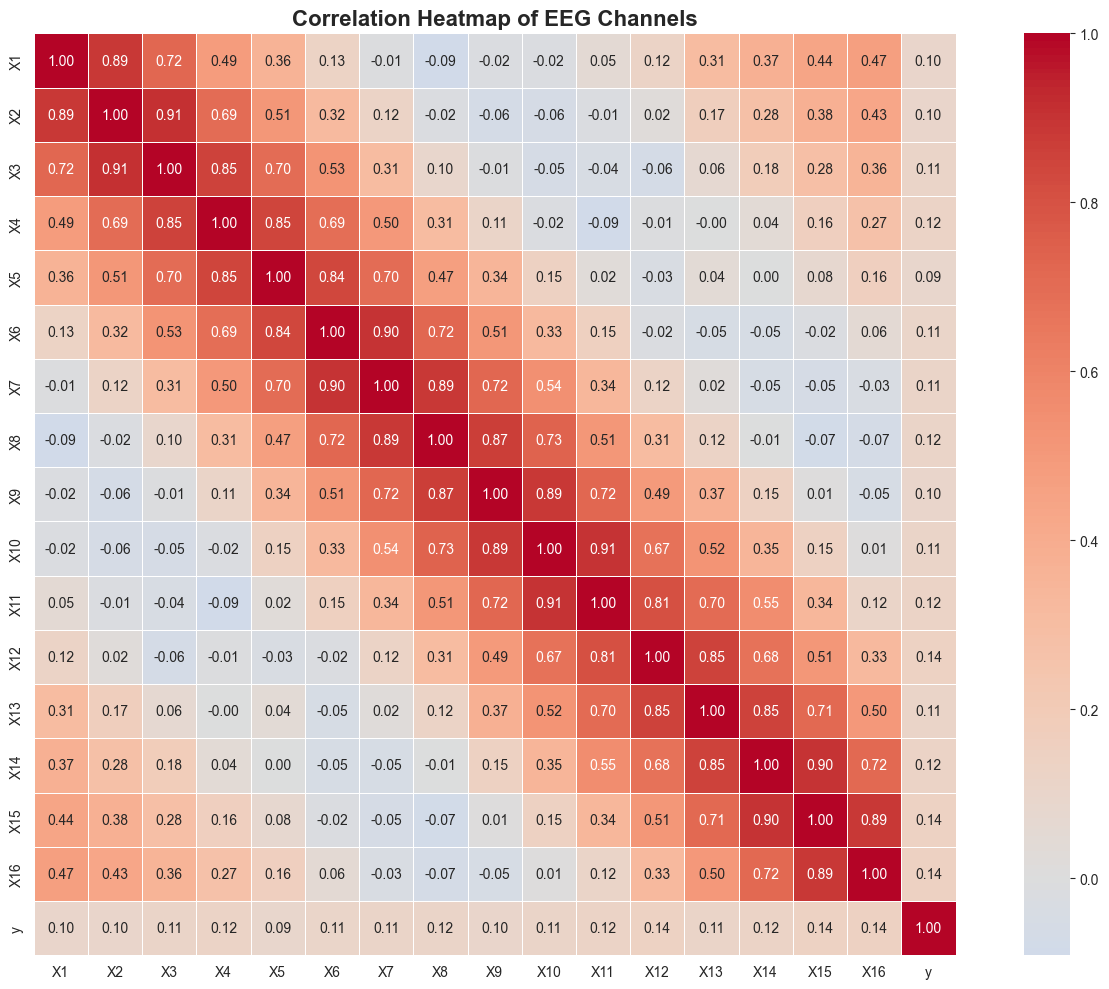

In [140]:
# Correlation heatmap
plt.figure(figsize=(14, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', 
            linewidths=0.5, center=0, square=True)
plt.title('Correlation Heatmap of EEG Channels', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

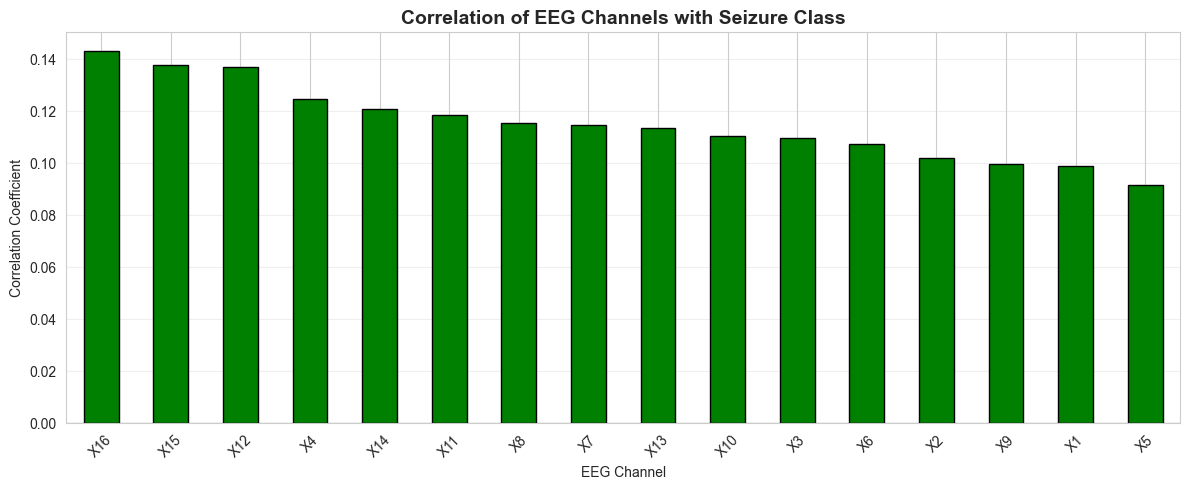

In [141]:
# Correlation with target variable
plt.figure(figsize=(12, 5))
target_corr = df[eeg_channels].corrwith(df['y']).sort_values(ascending=False)
colors_bar = ['green' if x > 0 else 'red' for x in target_corr.values]
target_corr.plot(kind='bar', color=colors_bar, edgecolor='black')
plt.title('Correlation of EEG Channels with Seizure Class', fontsize=14, fontweight='bold')
plt.xlabel('EEG Channel')
plt.ylabel('Correlation Coefficient')
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### EEG Signal Patterns by Class

Comparing signal characteristics across different seizure classes.

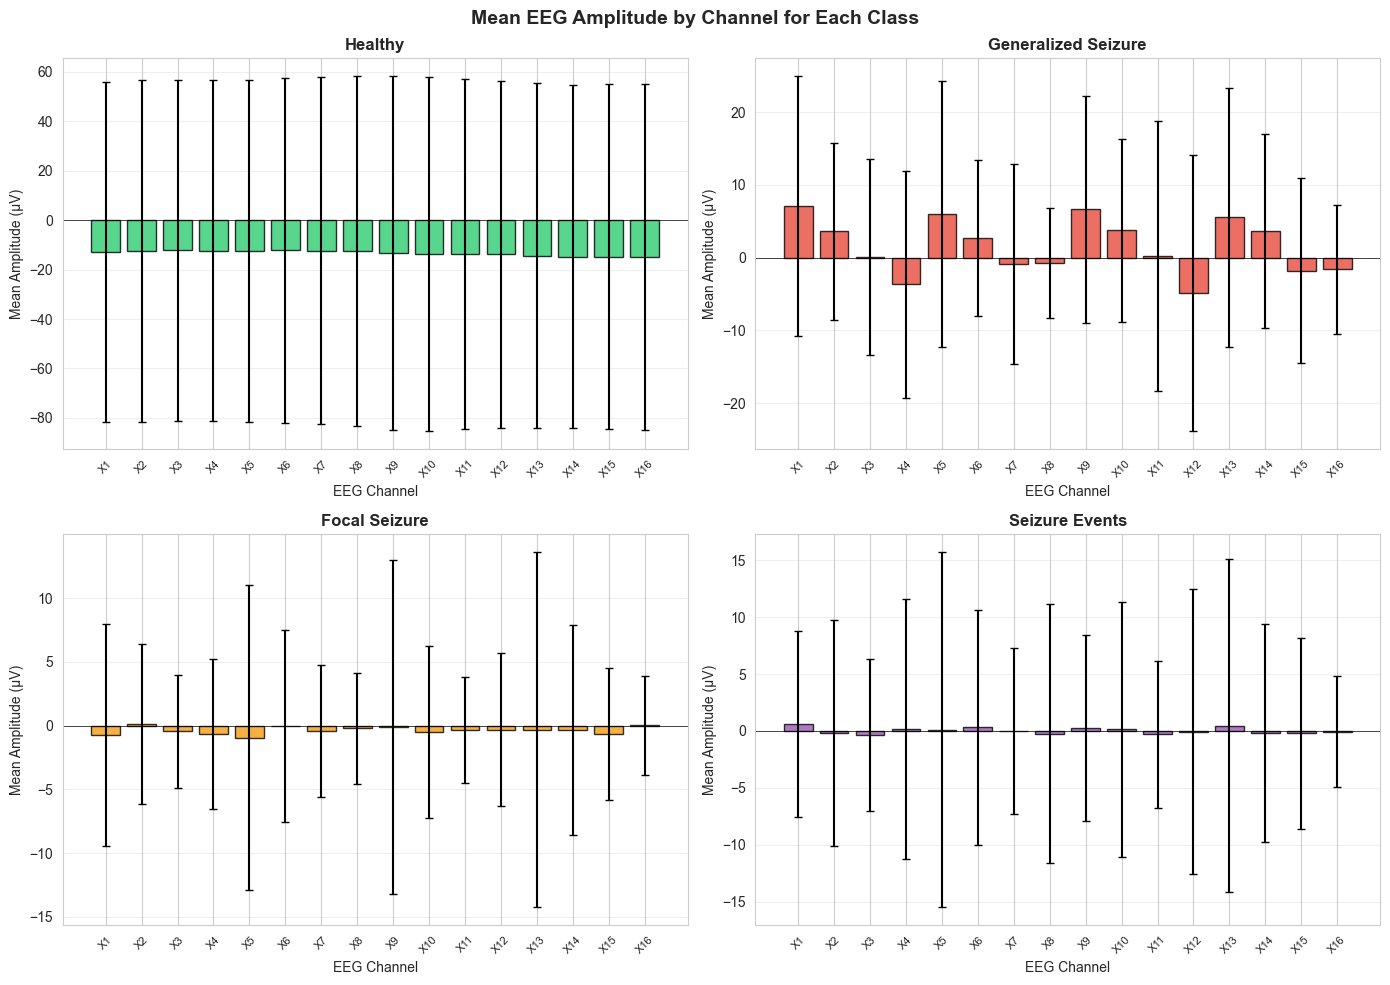

In [142]:
# Compare mean EEG amplitude across classes
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, cls in enumerate([0, 1, 2, 3]):
    class_data = df[df['y'] == cls][eeg_channels]
    mean_values = class_data.mean()
    std_values = class_data.std()
    
    axes[idx].bar(range(16), mean_values, yerr=std_values, capsize=3,
                  color=colors[idx], edgecolor='black', alpha=0.8)
    axes[idx].set_title(f'{class_labels[cls]}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('EEG Channel')
    axes[idx].set_ylabel('Mean Amplitude (μV)')
    axes[idx].set_xticks(range(16))
    axes[idx].set_xticklabels([f'X{i}' for i in range(1, 17)], rotation=45, fontsize=8)
    axes[idx].axhline(y=0, color='black', linestyle='-', linewidth=0.5)
    axes[idx].grid(axis='y', alpha=0.3)

plt.suptitle('Mean EEG Amplitude by Channel for Each Class', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

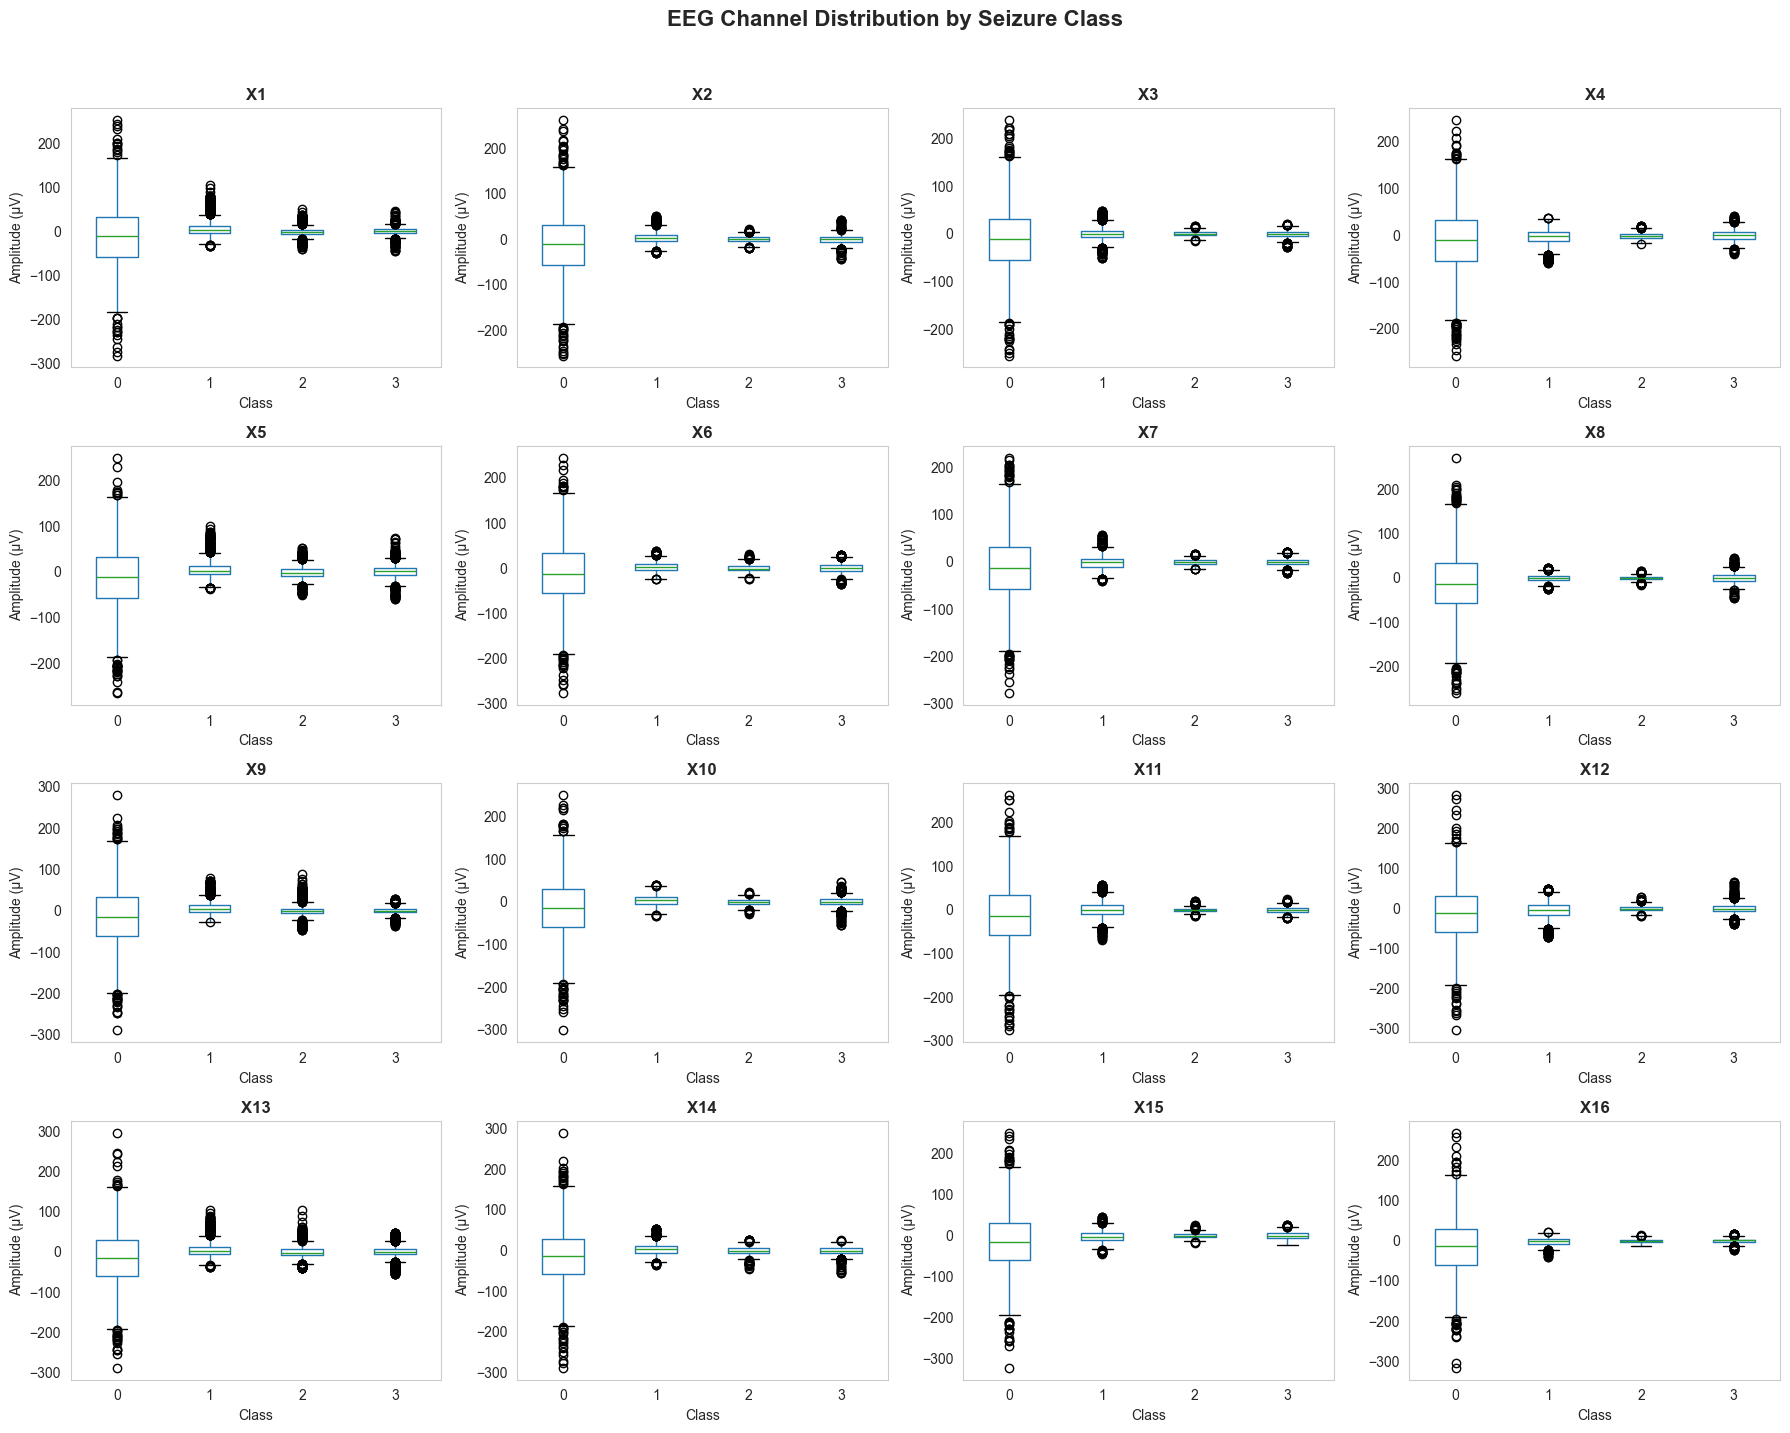

In [143]:
# Box plots comparing channels across classes
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
axes = axes.ravel()

for idx, channel in enumerate(eeg_channels):
    df.boxplot(column=channel, by='y', ax=axes[idx], grid=False)
    axes[idx].set_title(f'{channel}', fontweight='bold')
    axes[idx].set_xlabel('Class')
    axes[idx].set_ylabel('Amplitude (μV)')

plt.suptitle('EEG Channel Distribution by Seizure Class', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Outlier Detection

Using boxplots to identify outliers in EEG channels.

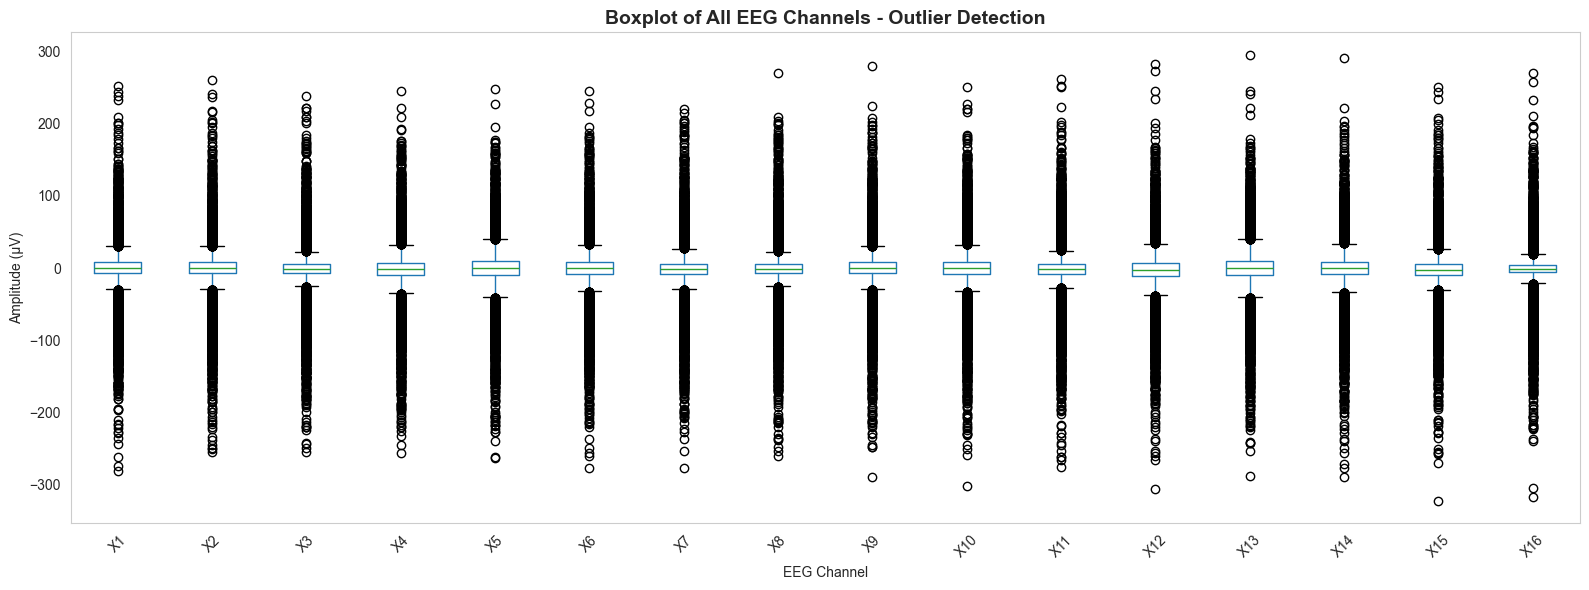


Outlier Count per Channel:
X1: 1550 (19.38%)
X2: 1367 (17.09%)
X3: 1564 (19.55%)
X4: 1319 (16.49%)
X5: 1241 (15.51%)
X6: 1266 (15.82%)
X7: 1444 (18.05%)
X8: 1519 (18.99%)
X9: 1613 (20.16%)
X10: 1329 (16.61%)
X11: 1680 (21.00%)
X12: 1336 (16.70%)
X13: 1272 (15.90%)
X14: 1305 (16.31%)
X15: 1406 (17.57%)
X16: 1574 (19.68%)


In [144]:
# Boxplot for outlier detection
plt.figure(figsize=(16, 6))
df[eeg_channels].boxplot(grid=False)
plt.title('Boxplot of All EEG Channels - Outlier Detection', fontsize=14, fontweight='bold')
plt.xlabel('EEG Channel')
plt.ylabel('Amplitude (μV)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Count outliers using IQR method
print("\nOutlier Count per Channel:")
for channel in eeg_channels:
    Q1 = df[channel].quantile(0.25)
    Q3 = df[channel].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df[channel] < Q1 - 1.5*IQR) | (df[channel] > Q3 + 1.5*IQR)).sum()
    print(f"{channel}: {outliers} ({outliers/len(df)*100:.2f}%)")


# Data Preprocessing

Preparing the EEG data for machine learning through Band pass filter,Stratified Splitting, Normalization

1. **Band-Pass Filtering**: 4th-order Butterworth filter (0.5-45 Hz) to remove drift and noise
2. **Stratified Splitting**: 70% Train, 15% Validation, 15% Test
3. **Normalization**: Z-score standardization (fit on training data only)

### Step 1: Prepare Raw Data

Extracting the raw EEG channels (X1-X16) for signal processing.

In [145]:
# Prepare raw data (16 EEG channels)
X_raw = df[eeg_channels].values
y = df['y'].values

print(f"X_raw shape: {X_raw.shape}")
print(f"y shape: {y.shape}")


X_raw shape: (8000, 16)
y shape: (8000,)


### Step 2: Signal Filtering (Band-Pass)

Applying a 4th-order zero-phase Butterworth band-pass filter (0.5-45 Hz) to remove:
- **Low-frequency drift** (< 0.5 Hz)
- **High-frequency muscle noise** (> 45 Hz)

The filter is applied independently to each EEG channel using `filtfilt` for zero-phase filtering.

In [146]:
from scipy.signal import butter, filtfilt

def butter_bandpass_filter(data, lowcut, highcut, fs, order=4):
    """Apply Butterworth band-pass filter"""
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    y = filtfilt(b, a, data, axis=0)
    return y

# Filter parameters
LOW_CUT = 0.5
HIGH_CUT = 45.0
FS = 256.0
ORDER = 4

print(f"Applying band-pass filter: {LOW_CUT}-{HIGH_CUT} Hz")

# Apply filter to all channels
X_filtered = butter_bandpass_filter(X_raw, LOW_CUT, HIGH_CUT, FS, ORDER)

print(f"Filtered shape: {X_filtered.shape}")


Applying band-pass filter: 0.5-45.0 Hz
Filtered shape: (8000, 16)


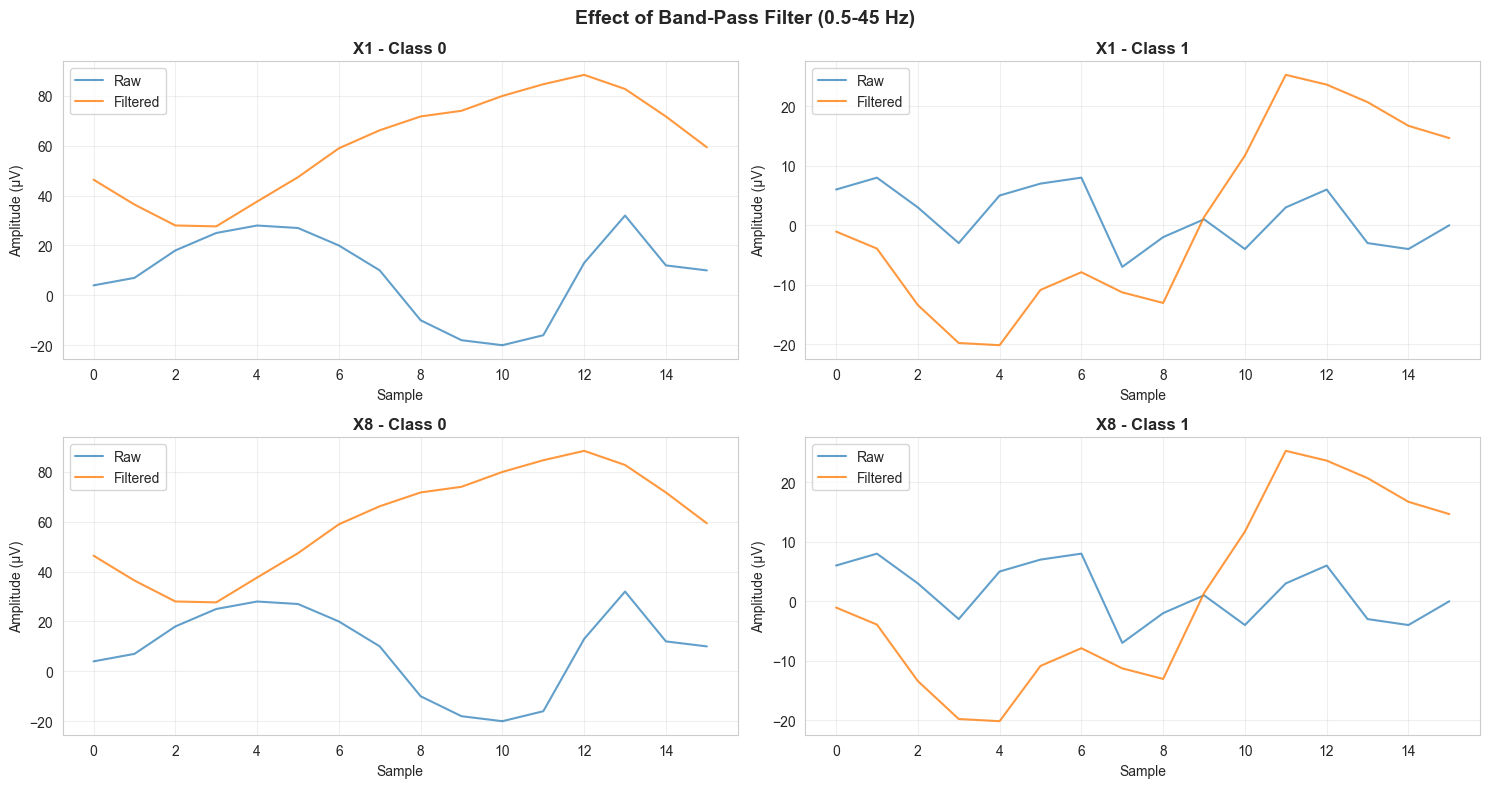

In [147]:
# Visualize filter effect
fig, axes = plt.subplots(2, 2, figsize=(15, 8))

sample_indices = [df[df['y'] == cls].index[0] for cls in range(4)]
sample_channels = ['X1', 'X8']

for idx, channel_name in enumerate(sample_channels):
    channel_idx = int(channel_name[1:]) - 1
    
    for cls_idx, sample_idx in enumerate(sample_indices[:2]):
        row = idx
        col = cls_idx
        
        axes[row, col].plot(X_raw[sample_idx, :], label='Raw', alpha=0.7, linewidth=1.5)
        axes[row, col].plot(X_filtered[sample_idx, :], label='Filtered', alpha=0.8, linewidth=1.5)
        axes[row, col].set_title(f'{channel_name} - Class {sample_idx // 2000}', fontweight='bold')
        axes[row, col].set_xlabel('Sample')
        axes[row, col].set_ylabel('Amplitude (μV)')
        axes[row, col].legend()
        axes[row, col].grid(alpha=0.3)

plt.suptitle('Effect of Band-Pass Filter (0.5-45 Hz)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


### Step 3: Stratified Data Splitting

Splitting the dataset into **Train (70%)**, **Validation (15%)**, and **Test (15%)** sets with stratification to maintain class balance.

**Important**: Splitting is done **before normalization** to prevent information leakage (normalization statistics will be computed on training data only).

In [148]:
from sklearn.model_selection import train_test_split

# Stratified split: 70% train, 15% val, 15% test
RANDOM_SEED = 42

# First split: 70% train, 30% temp
X_train_paper, X_temp, y_train_paper, y_temp = train_test_split(
    X_filtered, y, test_size=0.30, stratify=y, random_state=RANDOM_SEED
)

# Second split: 15% val, 15% test (50% of temp)
X_val_paper, X_test_paper, y_val_paper, y_test_paper = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_SEED
)

print(f"Train: {X_train_paper.shape} ({len(X_train_paper)/len(X_filtered)*100:.1f}%)")
print(f"Val:   {X_val_paper.shape} ({len(X_val_paper)/len(X_filtered)*100:.1f}%)")
print(f"Test:  {X_test_paper.shape} ({len(X_test_paper)/len(X_filtered)*100:.1f}%)")

# Show class distribution
for split_name, y_split in [("Train", y_train_paper), ("Val", y_val_paper), ("Test", y_test_paper)]:
    dist = np.bincount(y_split)
    print(f"{split_name:6} - Class 0:{dist[0]:5}, 1:{dist[1]:5}, 2:{dist[2]:5}, 3:{dist[3]:5}")


Train: (5600, 16) (70.0%)
Val:   (1200, 16) (15.0%)
Test:  (1200, 16) (15.0%)
Train  - Class 0: 1400, 1: 1400, 2: 1400, 3: 1400
Val    - Class 0:  300, 1:  300, 2:  300, 3:  300
Test   - Class 0:  300, 1:  300, 2:  300, 3:  300


### Step 4: Normalization (Standardization)

Applying Z-score normalization (zero mean, unit variance) to the data.

**Critical**: The scaler is **fit only on the training set** to prevent information leakage. The same statistics (mean and std from training) are used to transform validation and test sets.

In [149]:
from sklearn.preprocessing import StandardScaler

# Create and fit scaler on training data only
scaler_paper = StandardScaler()
scaler_paper.fit(X_train_paper)

# Transform all sets using training statistics
X_train_norm = scaler_paper.transform(X_train_paper)
X_val_norm = scaler_paper.transform(X_val_paper)
X_test_norm = scaler_paper.transform(X_test_paper)

print(f"Train - Mean: {X_train_norm.mean():.6f}, Std: {X_train_norm.std():.6f}")
print(f"Val   - Mean: {X_val_norm.mean():.6f}, Std: {X_val_norm.std():.6f}")
print(f"Test  - Mean: {X_test_norm.mean():.6f}, Std: {X_test_norm.std():.6f}")


Train - Mean: -0.000000, Std: 1.000000
Val   - Mean: 0.015748, Std: 1.015801
Test  - Mean: -0.000095, Std: 1.023666


### Step 5: One-Hot Encoding of Labels

Converting integer labels (0, 1, 2, 3) to one-hot encoded vectors for deep learning models that require categorical outputs.

In [150]:
from sklearn.preprocessing import LabelBinarizer

# One-hot encode labels
label_encoder = LabelBinarizer()
label_encoder.fit(y_train_paper)

y_train_onehot = label_encoder.transform(y_train_paper)
y_val_onehot = label_encoder.transform(y_val_paper)
y_test_onehot = label_encoder.transform(y_test_paper)

print(f"y_train_onehot: {y_train_onehot.shape}")
print(f"y_val_onehot:   {y_val_onehot.shape}")
print(f"y_test_onehot:  {y_test_onehot.shape}")

# Show example
print(f"\nExample: Label {y_train_paper[0]} → {y_train_onehot[0]}")


y_train_onehot: (5600, 4)
y_val_onehot:   (1200, 4)
y_test_onehot:  (1200, 4)

Example: Label 1 → [0 1 0 0]


In [151]:
# Save preprocessed data
output_path = './data/preprocessed/5_beed_bangalore_eeg_epilepsy_dataset.csv'

# Combine normalized train data with labels
df_preprocessed = pd.DataFrame(X_train_norm, columns=eeg_channels)
df_preprocessed['y'] = y_train_paper
df_preprocessed.to_csv(output_path, index=False)

print(f"✓ Preprocessed data saved: {output_path}")
print(f"  Shape: {df_preprocessed.shape}")


✓ Preprocessed data saved: ./data/preprocessed/5_beed_bangalore_eeg_epilepsy_dataset.csv
  Shape: (5600, 17)


# Machine Learning Models

Testing classification models on the preprocessed EEG data to establish baseline performance.

## Binary Classification: Healthy vs Seizure

Converting the problem to binary classification to show how Logistic Regression performs better.

In [152]:
# Convert multi-class to binary: 0 = Healthy, 1 = Any Seizure
y_binary = np.where(y_train_paper == 0, 0, 1)
y_test_binary = np.where(y_test_paper == 0, 0, 1)

print("Binary Class Distribution:")
print(f"Training Set - Healthy: {np.sum(y_binary == 0)}, Seizure: {np.sum(y_binary == 1)}")
print(f"Test Set - Healthy: {np.sum(y_test_binary == 0)}, Seizure: {np.sum(y_test_binary == 1)}")

# Train models on binary classification
lr_binary = LogisticRegression(max_iter=1000, random_state=42)
rf_binary = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)

lr_binary.fit(X_train_norm, y_binary)
rf_binary.fit(X_train_norm, y_binary)

# Predictions
y_pred_lr_binary = lr_binary.predict(X_test_norm)
y_pred_rf_binary = rf_binary.predict(X_test_norm)

# Accuracy
acc_lr_binary = accuracy_score(y_test_binary, y_pred_lr_binary)
acc_rf_binary = accuracy_score(y_test_binary, y_pred_rf_binary)

print("\n" + "=" * 60)
print("BINARY CLASSIFICATION RESULTS")
print("=" * 60)
print(f"\nLogistic Regression - Test Accuracy: {acc_lr_binary:.4f}")
print(classification_report(y_test_binary, y_pred_lr_binary, 
                          target_names=['Healthy', 'Seizure'], digits=4))

print(f"\nRandom Forest - Test Accuracy: {acc_rf_binary:.4f}")
print(classification_report(y_test_binary, y_pred_rf_binary, 
                          target_names=['Healthy', 'Seizure'], digits=4))

Binary Class Distribution:
Training Set - Healthy: 1400, Seizure: 4200
Test Set - Healthy: 300, Seizure: 900

BINARY CLASSIFICATION RESULTS

Logistic Regression - Test Accuracy: 0.7500
              precision    recall  f1-score   support

     Healthy     0.0000    0.0000    0.0000       300
     Seizure     0.7500    1.0000    0.8571       900

    accuracy                         0.7500      1200
   macro avg     0.3750    0.5000    0.4286      1200
weighted avg     0.5625    0.7500    0.6429      1200


Random Forest - Test Accuracy: 0.9967
              precision    recall  f1-score   support

     Healthy     1.0000    0.9867    0.9933       300
     Seizure     0.9956    1.0000    0.9978       900

    accuracy                         0.9967      1200
   macro avg     0.9978    0.9933    0.9955      1200
weighted avg     0.9967    0.9967    0.9967      1200

